## 05. Model Refinement & Product Analysis (Project Draft)

#### Goals: The goal of this notebook is to improve the revenue forecasting model by adding information about the time of year. I will also look at product sales to see which products bring in the most revenue.

#### Background & Next Steps:
* What I learned from previous models: In `04_model_evaluation_and_comparison.ipynb`, the models mostly used past sales to make predictions. Because they did not consider  seasonal changes, they struggled to predict the large increase in sales in late November, when revenue went above £350,000.
* Improving the model: I will add information such as the month, week of the year, and holiday periods to help the model recognize changes in sales throughout the year.
* Comparing the models: I will compare the new model with the previous models using MAE, RMSE, and R^2 on the same 80/20 data split.
* Product analysis: I will also look at which products generate the most revenue. This can help show which products are most important to the business and where inventory problems could happen.


## Section 1: Data Pipeline & Product Analysis

In [1]:
# 1. Importing necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
# 2. Cleaning and preparing the data
def load_and_clean_data(filepath):
    # Loading raw dataset
    raw_df = pd.read_csv(filepath, encoding='ISO-8859-1')
    df = raw_df.copy()

    # Renaming country values and removing duplicates
    df['Country'] = df['Country'].replace({'RSA': 'South Africa', 'EIRE': 'Ireland'})
    df = df.drop_duplicates()

    # Keeping valid sales and rows with a description
    df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]
    df = df.dropna(subset=['Description'])

    # Converting InvoiceDate to datetime
    df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%m/%d/%y %H:%M')

    # Calculating revenue
    df['Revenue'] = df['Quantity'] * df['UnitPrice']

    # Removing administrative and postage codes
    admin_codes = ['AMAZONFEE', 'B', 'DOT', 'M', 'POST', 'S', 'm']
    df_products = df[~df['StockCode'].isin(admin_codes)].copy()

    # Loading the raw data to identify cancelled orders
    grouped = raw_df.groupby(['CustomerID', 'StockCode'])['Quantity'].sum().reset_index()
    zero_net_orders = grouped[grouped['Quantity'] == 0][['CustomerID', 'StockCode']]

    # Removing cancelled orders
    merged = df_products.merge(
        zero_net_orders, 
        on=['CustomerID', 'StockCode'], 
        how='left', 
        indicator=True
    )
    clean_df = merged[merged['_merge'] == 'left_only'].drop(columns=['_merge']).copy()
    return clean_df

clean_df = load_and_clean_data('../data/raw/E-commerce_data.csv')
print(f"Cleaned records: {clean_df.shape[0]:,}")

Cleaned records: 521,208


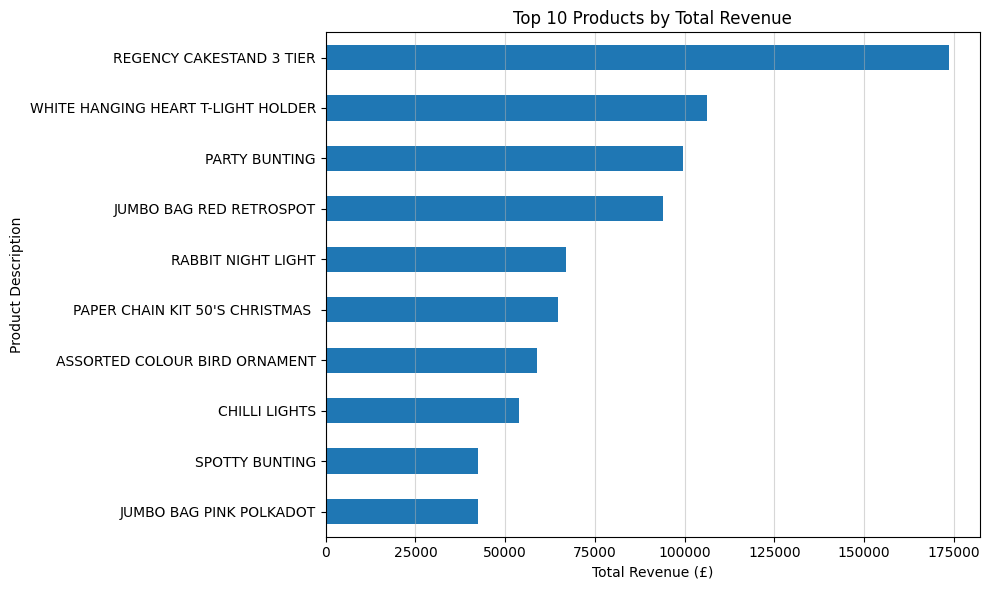

In [3]:
# 3. Viewing the top 10 products by total revenue
top_products = clean_df.groupby('Description')['Revenue'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind='barh', color='tab:blue')
plt.title('Top 10 Products by Total Revenue')
plt.xlabel('Total Revenue (£)')
plt.ylabel('Product Description')
plt.grid(axis='x', alpha=0.5)
plt.tight_layout()

plt.savefig('../images/top_10_products.png')
plt.show()

#### Product Revenue Findings

* Top Products: A small number of products generate a large share of revenue. The top two are `REGENCY CAKESTAND 3 TIER` (>£175,000) and `WHITE HANGING HEART T-LIGHT HOLDER` (>£100,000).
* Weekly Revenue: Revenue can depend heavily on sales of these top products, especially during high-volume weeks.
* Inventory Planning: These top products should be prioritized when planning inventory to help avoid running out during busy weeks.

## 2. Feature Engineering & Chronological Train/Test Split

#### I created two feature sets to test whether calendar information improves revenue forecasting:
1. Baseline Features (4 inputs): `Prior_Week_Revenue`, `Lag_2_Revenue`, `Prior_Week_Orders`, and `Rolling_4_Week_Revenue`.
2. Calendar Features (6 inputs): The baseline features plus `week_of_year` and `is_holiday_season` (weeks 46–49).

#### I used an 80/20 chronological split, with 39 weeks for training and 10 weeks for testing, to avoid using future data when making predictions.


In [4]:
# 4. Weekly aggregation and feature generation

weekly_base = clean_df.groupby(pd.Grouper(key='InvoiceDate', freq='W-SUN')).agg(
    Revenue=('Revenue', 'sum'),
    Order_Count=('InvoiceNo', 'nunique')
).reset_index().iloc[:-1].copy()

# Filling the holiday closure week
weekly_interp = weekly_base.copy()
weekly_interp['Revenue'] = weekly_interp['Revenue'].replace(0, np.nan).interpolate(method='linear')
weekly_interp['Order_Count'] = weekly_interp['Order_Count'].replace(0, np.nan).interpolate(method='linear')

# Create lag, rolling, and calendar features
weekly_interp['Prior_Week_Revenue'] = weekly_interp['Revenue'].shift(1)
weekly_interp['Lag_2_Revenue'] = weekly_interp['Revenue'].shift(2)
weekly_interp['Prior_Week_Orders'] = weekly_interp['Order_Count'].shift(1)
weekly_interp['Rolling_4_Week_Revenue'] = weekly_interp['Revenue'].shift(1).rolling(window=4).mean()

weekly_interp['week_of_year'] = weekly_interp['InvoiceDate'].dt.isocalendar().week.astype(int)
weekly_interp['is_holiday_season'] = weekly_interp['week_of_year'].isin([46, 47, 48, 49]).astype(int)

clean_interp = weekly_interp.dropna().reset_index(drop=True)

# Set up baseline and calendar features
baseline_features = ['Prior_Week_Revenue', 'Lag_2_Revenue', 'Prior_Week_Orders', 'Rolling_4_Week_Revenue']
calendar_features = baseline_features + ['week_of_year', 'is_holiday_season']

# Split the data chronologically
split_idx = int(len(clean_interp) * 0.8)

X_train_base = clean_interp.loc[:split_idx - 1, baseline_features]
X_test_base = clean_interp.loc[split_idx:, baseline_features]

X_train_cal = clean_interp.loc[:split_idx - 1, calendar_features]
X_test_cal = clean_interp.loc[split_idx:, calendar_features]

y_train = clean_interp.loc[:split_idx - 1, 'Revenue']
y_test = clean_interp.loc[split_idx:, 'Revenue']

print(f"Train weeks: {len(X_train_base)} | Test weeks: {len(X_test_base)}")

Train weeks: 39 | Test weeks: 10


In [5]:
# 5. Training and comparing models

# Naive baseline
pred_naive = X_test_base['Prior_Week_Revenue']

# Training models
lr_base = LinearRegression().fit(X_train_base, y_train)
pred_lr_base = lr_base.predict(X_test_base)

ridge_base = Ridge(alpha=1.0).fit(X_train_base, y_train)
pred_ridge_base = ridge_base.predict(X_test_base)

lr_cal = LinearRegression().fit(X_train_cal, y_train)
pred_lr_cal = lr_cal.predict(X_test_cal)

ridge_cal = Ridge(alpha=1.0).fit(X_train_cal, y_train)
pred_ridge_cal = ridge_cal.predict(X_test_cal)

# Calculating model performance
def evaluate_predictions(y_true, y_pred):
    return [
        round(mean_absolute_error(y_true, y_pred), 2),
        round(np.sqrt(mean_squared_error(y_true, y_pred)), 2),
        round(r2_score(y_true, y_pred), 4)
    ]

results = [
    ["Naive Baseline", "Prior Week", *evaluate_predictions(y_test, pred_naive)],
    ["Linear Regression", "Baseline", *evaluate_predictions(y_test, pred_lr_base)],
    ["Ridge Regression", "Baseline", *evaluate_predictions(y_test, pred_ridge_base)],
    ["Linear Regression", "Baseline + Calendar", *evaluate_predictions(y_test, pred_lr_cal)],
    ["Ridge Regression", "Baseline + Calendar", *evaluate_predictions(y_test, pred_ridge_cal)]
]

results_df = pd.DataFrame(
    results,
    columns=["Model", "Features", "MAE", "RMSE", "R2"]
)

display(results_df)

,Model,Features,MAE,RMSE,R2
0,Naive Baseline,Prior Week,59202.27,69075.38,-0.7327
1,Linear Regression,Baseline,61802.95,71983.25,-0.8816
2,Ridge Regression,Baseline,61802.99,71983.28,-0.8816
3,Linear Regression,Baseline + Calendar,109747.60,125209.22,-4.6930
4,Ridge Regression,Baseline + Calendar,109727.63,125183.77,-4.6907


#### Calendar Features and Model Performance
* Model Performance: Adding calendar features made the model worse. MAE increased from £61.8k to £109.7k, and R² decreased from -0.88 to -4.69.
* Holiday Feature: Weeks 46–49 were only in the test data, so `is_holiday_season` was 0 for all training weeks and did not help the model.
* Week of Year: `week_of_year` did not capture seasonal patterns well because the data only covered one year.
* Conclusion: The calendar features did not improve the model. Recent revenue and order patterns worked better for this dataset.

#### Random Forest and Final Blend
* Random Forest: Since the linear models did not handle revenue changes well, I trained a Random Forest using the 4 baseline features.
* Weight Selection: I tested different weights from 0% to 100% in 5% increments. The best result was 35% Naive and 65% Random Forest.
* Final Model: Cell 6 uses the 35/65 blend, combining the previous week's revenue with the Random Forest predictions.


In [6]:
# 6. Training Random Forest and creating the final blend

rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=4,
    random_state=42
)
rf_model.fit(X_train_base, y_train)
pred_rf = rf_model.predict(X_test_base)

# Combine Naive and Random Forest predictions
pred_opt_blend = (0.35 * pred_naive) + (0.65 * pred_rf)

mae_blend, rmse_blend, r2_blend = evaluate_predictions(
    y_test, pred_opt_blend
)

print("--- Final Blend: 35% Naive + 65% Random Forest ---")
print(f"MAE:  £{mae_blend:,.2f}")
print(f"RMSE: £{rmse_blend:,.2f}")
print(f"R²:   {r2_blend:.4f}")

--- Final Blend: 35% Naive + 65% Random Forest ---
MAE:  £55,670.16
RMSE: £63,582.15
R²:   -0.4680


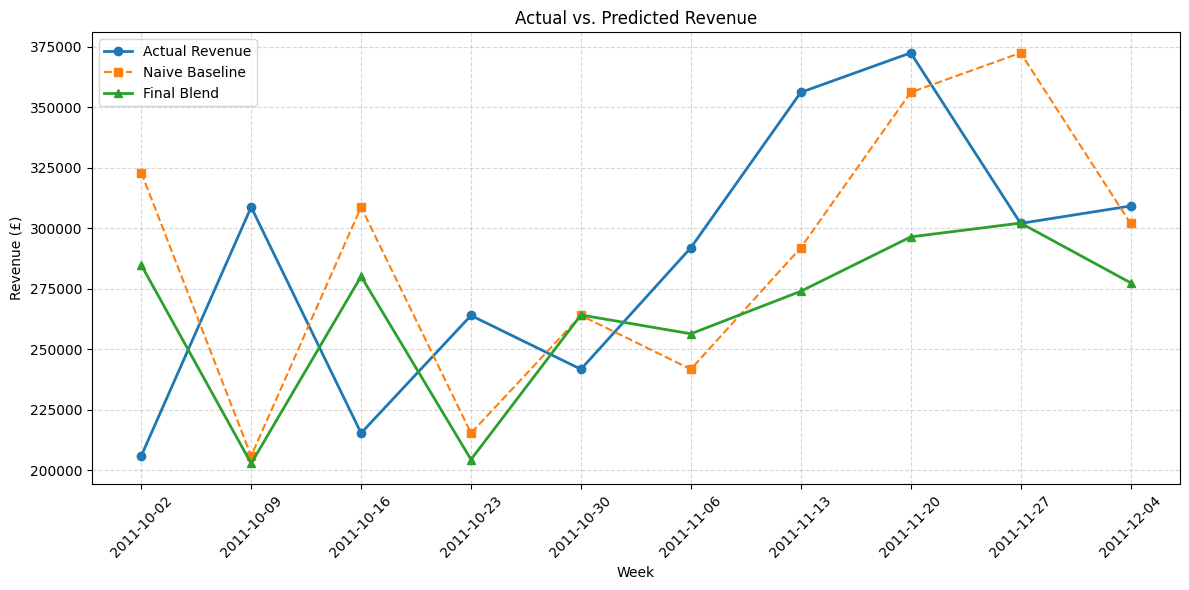

In [7]:
# 7. Comparing actual and predicted revenue

plt.figure(figsize=(12, 6))
test_weeks = clean_interp.loc[split_idx:, 'InvoiceDate'].dt.strftime('%Y-%m-%d')

plt.plot(
    test_weeks, y_test,
    marker='o', linewidth=2,
    label='Actual Revenue'
)

plt.plot(
    test_weeks, pred_naive,
    marker='s', linestyle='--',
    label='Naive Baseline'
)

plt.plot(
    test_weeks, pred_opt_blend,
    marker='^', linewidth=2,
    label='Final Blend'
)

plt.title('Actual vs. Predicted Revenue')
plt.xlabel('Week')
plt.ylabel('Revenue (£)')
plt.xticks(rotation=45)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.tight_layout()

# Save figure for the report
plt.savefig('../images/actual_vs_blend.png')
plt.show()

## 5. Model Results & Business Implications

#### Model Results:
* The naive baseline had a test MAE of £59,202.27, an RMSE of £69,075.38, and an R^2 of -0.7327.
* Adding calendar features made the linear models perform worse, with MAE increasing to about £109.7k, RMSE to about £125.2k, and R^2 to -4.69.
* Alternative experiments which included: target differencing, feature scaling, and behavioral features (average order value), did not outperform the baseline, so they were streamlined out of the final workflow.
* The best approach was the 35% Naive / 65% Random Forest blend, which achieved an MAE of £55,670.16, an RMSE of £63,582.15, and an R^ of -0.4680.
* This suggests that recent weekly revenue patterns were more useful for this dataset than the added calendar features.

#### Key Takeaways:
* The calendar features did not improve the model because the training data covered only 39 weeks, and the holiday weeks appeared only in the test set.
* The blended model performed best because it combined recent weekly revenue patterns with the Random Forest predictions.
* The model is useful for planning, but the forecast error is still large enough that it should not be used as the only basis for inventory decisions.

#### Business Implications:
* Forecasts can help with warehouse and inventory planning, especially during higher-volume weeks.
* High-revenue products should receive more attention when planning inventory to reduce the risk of stockouts.
* More years of transaction data would make it possible to better measure and model seasonal patterns.
